# 08 · The final annotation set

One Fit / No Fit label per in-domain pair (D41, D47), built by the user-approved rule of
26 Sep 2026:

| Case | Final label |
|---|---|
| both humans agree | theirs |
| both humans split | the LLM (committed instrument `5d986c82`, haiku) breaks the tie |
| one human | that human |
| no human | the LLM |

Everything below is read from the committed record (`output/annotation/a2-final-report.json`)
and manifest (`docs/data/manifests/a2-final-labels.csv`). This notebook defines nothing.
Rebuild with `uv run python -m candidate_screener.evaluation.final_set --build`.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.evaluation import final_set

reporting.style(plt)
report = json.loads(final_set.REPORT_JSON.read_text(encoding="utf-8"))
labels = final_set.load()
print(f"rule v{report['rule_version']}: " + "; ".join(report["rule"]))
print(f"{len(labels)} pairs, {labels.jd_id.nunique()} JDs")

rule v1: both humans agree -> their label; both humans split -> the LLM's label; one human -> that human's label; no human -> the LLM's label
600 pairs, 60 JDs


## Where each label came from

Tier counts per stratum, and in total. The LLM decides only where the two humans split.

In [2]:
tiers = pd.DataFrame({s: v["tiers"] for s, v in report["scopes"].items()})
tiers

,generic,targeted,total
humans_agree,93,126,219
llm_breaks_tie,33,74,107
single_human,274,0,274
llm_only,0,0,0


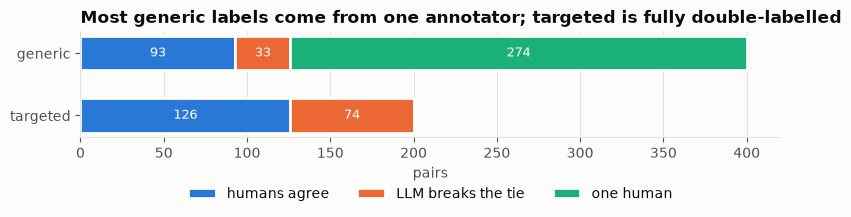

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.6))
shown = [t for t in final_set.TIERS if tiers.loc[t, "total"] > 0]
names = {"humans_agree": "humans agree", "llm_breaks_tie": "LLM breaks the tie",
         "single_human": "one human"}
left = pd.Series(0, index=["generic", "targeted"])
for tier, color in zip(shown, reporting.SERIES):
    width = tiers.loc[tier, ["generic", "targeted"]]
    ax.barh(width.index, width, left=left, color=color, edgecolor=reporting.SURFACE,
            linewidth=2, label=names[tier], height=0.55)
    for y, (w, l) in enumerate(zip(width, left)):
        if w >= 20:
            ax.text(l + w / 2, y, f"{w}", ha="center", va="center", color="white", fontsize=9)
    left += width
ax.invert_yaxis()
ax.set_xlabel("pairs")
ax.set_title("Most generic labels come from one annotator; targeted is fully double-labelled")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.grid(axis="y", visible=False)
plt.tight_layout()

## The final set beside each annotator

Fit rate per source. The final set sits between the harsher `yc` and the more generous `van`.

In [4]:
pd.DataFrame({s: v["fit_rate"] for s, v in report["scopes"].items()}).round(3)

,generic,targeted,total
final_label,0.625,0.585,0.612
yc,0.598,0.420,0.538
van,0.810,0.640,0.706
llm,0.618,0.610,0.615


## Inter-annotator agreement — reported, with no target (D44)

Fit / No Fit agreement and Cohen's kappa on the pairs both raters labelled, with 95% CIs
resampling JDs. This is the context every system figure is read against; nothing is
expected to hit it.

In [5]:
rows = []
for scope, v in report["scopes"].items():
    for pair, b in v["inter_annotator"].items():
        rows.append({"scope": scope, "pair": pair.replace("_vs_", " vs "), "n": b["n_pairs"],
                     "agreement": f"{b['agreement']:.3f} [{b['agreement_ci'][0]:.2f}, {b['agreement_ci'][1]:.2f}]",
                     "kappa": f"{b['kappa']:.3f} [{b['kappa_ci'][0]:.2f}, {b['kappa_ci'][1]:.2f}]"})
pd.DataFrame(rows).pivot(index="pair", columns="scope", values="kappa")

scope,generic,targeted,total
pair,,,
van vs llm,"0.431 [0.29, 0.57]","0.339 [0.17, 0.48]","0.371 [0.25, 0.48]"
yc vs llm,"0.581 [0.48, 0.68]","0.362 [0.18, 0.54]","0.505 [0.41, 0.60]"
yc vs van,"0.419 [0.27, 0.58]","0.292 [0.15, 0.43]","0.353 [0.25, 0.46]"


In [6]:
pd.DataFrame(rows).pivot(index="pair", columns="scope", values="agreement")

scope,generic,targeted,total
pair,,,
van vs llm,"0.746 [0.66, 0.82]","0.690 [0.60, 0.77]","0.712 [0.65, 0.77]"
yc vs llm,"0.800 [0.75, 0.85]","0.670 [0.57, 0.77]","0.757 [0.71, 0.81]"
yc vs van,"0.738 [0.64, 0.83]","0.630 [0.55, 0.71]","0.672 [0.61, 0.74]"


**Reading.** Two trained annotators agree on Fit / No Fit for about two pairs in three
(kappa ≈ 0.35). The LLM agrees with `yc` more than with `van`. The final set is a
documented panel rule over these readers, not ground truth. A system's figure against it
is agreement with that rule. The agreement of each annotator *with the final set* is
inflated by construction, since each contributed, and is not shown as a ceiling.